# Module 2 — Pareto Analysis

Part of the Root-Cause Analysis Playbook. Program and progress: [CURRICULUM.md](CURRICULUM.md).

## Why you're here: what this module is for

- A team can fix only a few problems at a time. Pareto analysis ranks the causes, so the first project goes where a fix removes the most pain.
- In DMAIC (Define, Measure, Analyze, Improve, Control), this is a **Define** tool: it chooses *which* problem gets a project.
- The main trap: ranking by the wrong measure. The cause that happens most often is often not the one that costs most.

**What this module produces:**
1. Two Pareto charts of the same incidents, one by count and one by user-hours lost, and the project each would pick.
2. A one-sentence problem statement (what, when, how big) for the chosen project.
3. A nested Pareto (the same chart, inside the top cause), and a before-and-after check of the fix.

## From the curriculum

> ## <u>Module 2 — Pareto Analysis</u>
>
> **DMAIC phase:** Define (choosing which problem deserves a project).
>
> **Concepts**
> - The Pareto chart: categories sorted from largest to smallest, bars plus a
>   cumulative-share line, and the "vital few" categories that carry most of
>   the effect
> - The Pareto principle (the "80/20 rule") as a rule of thumb to check, not a
>   law
> - Counting the right thing: a Pareto by number of incidents and a Pareto by
>   impact (time lost by users) can rank the same causes very differently
> - One huge incident can put a category on top of an impact Pareto; check the
>   largest single incident before choosing
> - Second-level (nested) Pareto: drilling into the top bar
> - Before-and-after Pareto: checking a fix by re-running the chart
>
> **Why it matters**
> A team can only run a few root-cause projects at once. Pareto analysis picks
> the one where a fix removes the most pain, and it is the usual first chart in
> a DMAIC Define phase.
>
> **Worked example**
> Fresh, simulated: one year of incidents on a company's data platform (649
> incidents), with cause, minutes to resolve and users affected. It is
> simulated because the lesson needs a known case where the count ranking and
> the impact ranking disagree. Jan–Jun is used to choose a project, Jul–Dec to
> check the fix:
> - By count, late upstream files are the top cause (39.8% of incidents).
> - By impact, upstream schema changes are (71.8% of user-hours lost, from
>   8.2% of incidents).
> - A nested Pareto inside schema changes points at renamed columns. After a
>   fix from 1 Jul, renamed-column incidents fall from 12 to 2, though the
>   untargeted kinds fall too.
> - The Jul–Dec impact Pareto has a new top category, mostly one incident,
>   though that kind of incident happened in both halves.
>
> Sidenote: the E02 margin investigation (an earlier exercise), which used a
> loss Pareto without naming it.
>
> **Resources**
> - [Pareto chart](https://en.wikipedia.org/wiki/Pareto_chart) (Wikipedia,
>   ~5 min, verified): the chart, its cumulative line, and its place among the
>   seven basic tools of quality.
> - [Pareto principle](https://en.wikipedia.org/wiki/Pareto_principle)
>   (Wikipedia, ~10 min, verified): origin (Vilfredo Pareto, 1906), Joseph
>   Juran's "vital few", and why 80/20 is a rule of thumb, not a law.
>
> **Exercise type:** pick the project when the goal changes from user pain to
> on-call workload. Fully worked.
>
> **Interview angle:** "You have 400 open bugs and capacity to fix 20. Which
> ones?"

## Lesson

### What a Pareto chart shows

- **Bars:** one per category (here: per cause of incidents), sorted from largest to smallest.
- **Line:** the cumulative share. At each bar, it shows what share of the total that bar and all bars to its left add up to.
- **The vital few:** the first few bars that together carry most of the total. They are where a project pays off most.

### The 80/20 rule is a rule of thumb, not a law

The idea comes from Vilfredo Pareto, who noticed in 1906 that about 20% of people owned about 80% of the land in Italy. Joseph Juran applied it to quality problems: a few causes produce most of the defects. Real data can be 90/10, 70/30, or not concentrated at all. The chart is how you check.

### Three traps

1. **The wrong measure.** Counting incidents treats a 5-minute glitch the same as a 2-day outage. Rank by the measure that matches the goal: user pain, money, on-call workload.
2. **One huge incident.** On an impact measure, a single extreme event can put a category on top. Check the largest single incident before choosing.
3. **Categories that are too broad or too fine.** One giant "other" bar, or one real cause split across five small bars, both hide where the problem is.

### Where it sits in DMAIC

Mainly in **Define**: it picks the project. The same chart, re-run after a fix, also checks the fix in **Improve** and **Control**.

## Worked example: one year of data-platform incidents

**Data choice: fresh, simulated.** The lesson needs a case where the count ranking and the impact ranking disagree, with the truth known. Every number in the simulation is a chosen example (`common.simulate_incidents`, fixed seed).

**Each row is one incident:** its date, its cause (and, for schema changes, the kind of change), minutes to resolve, and users affected.

**Impact measure (chosen):** user-hours lost = minutes to resolve ÷ 60 × users affected. It combines how long an incident lasts with how many people it hits.

**The goal:** less pain for the people who use the data, measured as user-hours lost.

**The plan:** Jan–Jun is used to choose a project. A fix goes live on 1 Jul. Jul–Dec checks whether the fix worked.

**Where this was already done, unnamed:** in the user's E02 margin investigation (`AI Analyst Workspace/Reports/E02_Summary.md`, a local file), a loss Pareto showed that the worst 217 of 1,022 loss-making orders (21%) carried 80% of the loss. 217 orders are too many to fix one by one, so the fix had to be a pricing rule.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import common
from common import show, BLUE, ORANGE, GREY

inc = common.simulate_incidents()
h1 = inc[inc["date"] < "2025-07-01"]
h2 = inc[inc["date"] >= "2025-07-01"]
print("What is in the data? (simulated)")
print(f"  incidents = {len(inc):,}")
print(f"  dates = {inc['date'].min():%Y-%m-%d} to {inc['date'].max():%Y-%m-%d}")
print(f"  causes = {inc['category'].nunique()}")
print(f"  missing values = {int(inc.isna().sum().sum())}")
n_kind = (inc["sub_cause"] != "").sum()
print(f"  kind of change: filled for the {n_kind} \"Upstream schema change\" incidents, blank (not applicable) for the other {len(inc) - n_kind}")
print(f"  Jan-Jun (used to choose a project) = {len(h1):,} incidents")
print(f"  Jul-Dec (used to check the fix) = {len(h2):,} incidents")

What is in the data? (simulated)
  incidents = 649
  dates = 2025-01-01 to 2025-12-31
  causes = 8
  missing values = 0
  kind of change: filled for the 31 "Upstream schema change" incidents, blank (not applicable) for the other 618
  Jan-Jun (used to choose a project) = 304 incidents
  Jul-Dec (used to check the fix) = 345 incidents


**Observation:** 649 incidents over one year, 8 causes, no missing values (the data is simulated, so it is clean on purpose). The first half-year has 304 incidents.

### Part 1 — Which causes produce the most incidents? (Jan–Jun)

In [2]:
def pareto_table(df, value, label):
    """One row per cause, sorted by `value`, with its share and the cumulative share."""
    t = (df.groupby("category").agg(incidents=("incident_id", "size"), user_hours=("user_hours_lost", "sum"),
                                    largest=("user_hours_lost", "max"))
         .sort_values(value, ascending=False).reset_index())
    t["share"] = t[value] / t[value].sum()
    t["cumulative"] = t["share"].cumsum()
    return t


def pareto_chart(t, value, ylabel, title, note, split=False):
    """split=True: each bar = the rest of that cause (light, from the base) + its largest single incident (dark, on top)."""
    fig, ax = plt.subplots(figsize=(8, 4))
    x = np.arange(len(t))
    if split:
        ax.bar(x, t[value] - t["largest"], color="#9cc4f2", label="rest of the cause")
        ax.bar(x, t["largest"], bottom=t[value] - t["largest"], color="#184f95", label="largest single incident")
        ax.legend(fontsize=8, frameon=False, loc="center right", bbox_to_anchor=(0.98, 0.35))
    else:
        ax.bar(x, t[value], color=BLUE)
    ax.set_xticks(x, t["category"], rotation=30, ha="right", fontsize=8.5)
    ax.set_ylabel(ylabel)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax2 = ax.twinx()
    ax2.plot(x, t["cumulative"], color=ORANGE, marker="o", lw=1.5)
    ax2.axhline(0.8, color=GREY, ls="--", lw=1)
    ax2.set_ylim(0, 1.05)
    ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax2.set_ylabel("cumulative share (orange line)")
    ax2.text(len(t) - 0.55, 0.815, "80%", fontsize=8, color=GREY, ha="right")
    ax2.grid(False)
    ax2.spines["right"].set_visible(True)
    ax.set_title(title, fontsize=10, loc="left")
    ax.text(0.98, 0.55, note, transform=ax.transAxes, ha="right", fontsize=8.5, color="#333333")
    plt.tight_layout(); plt.show()


by_count = pareto_table(h1, "incidents", "incidents")
print("Incidents by cause, Jan-Jun:\n")
show(pd.DataFrame({"cause": by_count["category"], "incidents": by_count["incidents"],
                   "% of incidents": by_count["share"].map("{:.1%}".format),
                   "cumulative %": by_count["cumulative"].map("{:.1%}".format)}))

Incidents by cause, Jan-Jun:

cause                         incidents  % of incidents  cumulative %
Late upstream file                  121           39.8%         39.8%
Failed scheduled job                 70           23.0%         62.8%
Permission error                     30            9.9%         72.7%
Upstream schema change               25            8.2%         80.9%
Dashboard bug                        23            7.6%         88.5%
Bad data (duplicates, nulls)         19            6.2%         94.7%
Other                                14            4.6%         99.3%
Warehouse outage                      2            0.7%        100.0%


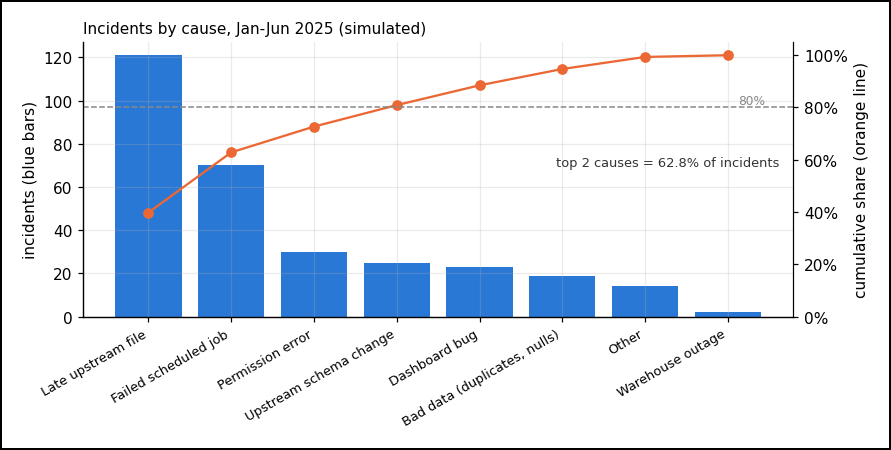

In [3]:
pareto_chart(by_count, "incidents", "incidents (blue bars)", "Incidents by cause, Jan-Jun 2025 (simulated)",
             f"top 2 causes = {by_count['cumulative'].iloc[1]:.1%} of incidents")

**Observation:** 4 causes reach 80% of incidents (80.9%). The top 2 alone, late upstream files (39.8%) and failed scheduled jobs (23.0%), are 62.8%. By count, the first project would be the top bar: late upstream files.

But a count treats a 5-minute glitch the same as a 2-day outage. The next question:

### Part 2 — Which causes cost the most user-hours lost? (Jan–Jun)

The last two columns check the "one huge incident" trap: is a bar mostly one incident?

In [4]:
by_impact = pareto_table(h1, "user_hours", "user-hours")
print("User-hours lost by cause, Jan-Jun (user-hours = minutes to resolve ÷ 60 × users affected):\n")
show(pd.DataFrame({
    "cause": by_impact["category"],
    "user-hours lost": by_impact["user_hours"].map("{:,.0f}".format),
    "% of user-hours lost": by_impact["share"].map("{:.1%}".format),
    "cumulative %": by_impact["cumulative"].map("{:.1%}".format),
    "incidents": by_impact["incidents"],
    "largest single incident": by_impact["largest"].map("{:,.0f}".format),
    "largest as % of cause's user-hours": (by_impact["largest"] / by_impact["user_hours"]).map("{:.0%}".format),
}))

User-hours lost by cause, Jan-Jun (user-hours = minutes to resolve ÷ 60 × users affected):

cause                         user-hours lost  % of user-hours lost  cumulative %  incidents  largest single incident  largest as % of cause's user-hours
Upstream schema change                 36,928                 71.8%         71.8%         25                    7,216                                 20%
Warehouse outage                        6,874                 13.4%         85.1%          2                    5,418                                 79%
Bad data (duplicates, nulls)            4,357                  8.5%         93.6%         19                      570                                 13%
Late upstream file                      1,616                  3.1%         96.8%        121                       67                                  4%
Dashboard bug                           1,163                  2.3%         99.0%         23                      178                     

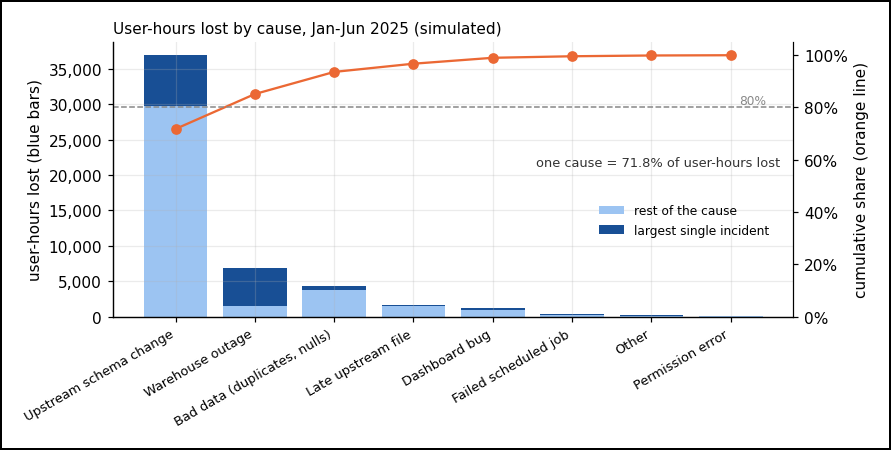

In [5]:
pareto_chart(by_impact, "user_hours", "user-hours lost (blue bars)", "User-hours lost by cause, Jan-Jun 2025 (simulated)",
             f"one cause = {by_impact['share'].iloc[0]:.1%} of user-hours lost", split=True)

**Observation:** upstream schema changes cost 71.8% of all user-hours lost, from only 25 incidents. Late upstream files, the top cause by count, cost 3.1%.

Is any top bar mostly one incident?
- Upstream schema change: 25 incidents, the largest = 7,216 of 36,928 user-hours (20%). No single incident dominates, so the bar doesn't rest on one event.
- Warehouse outage: 2 incidents, the largest = 5,418 of 6,874 user-hours (79%). Mostly one event.

### Part 3 — Which project?

The two rankings side by side, to see where they disagree:

In [6]:
ranks = pd.DataFrame({"cause": by_count["category"], "rank by incidents": range(1, len(by_count) + 1)}).merge(
    pd.DataFrame({"cause": by_impact["category"], "rank by user-hours lost": range(1, len(by_impact) + 1)}))
print("The same causes, ranked two ways (Jan-Jun):\n")
show(ranks)

The same causes, ranked two ways (Jan-Jun):

cause                         rank by incidents  rank by user-hours lost
Late upstream file                            1                        4
Failed scheduled job                          2                        6
Permission error                              3                        8
Upstream schema change                        4                        1
Dashboard bug                                 5                        5
Bad data (duplicates, nulls)                  6                        3
Other                                         7                        7
Warehouse outage                              8                        2


**Conclusion:** the two measures pick different projects. Late upstream files are first by count but fourth by user-hours lost. Upstream schema changes are fourth by count but first by user-hours lost.

The goal is less pain for the data's users, measured as user-hours lost, so the project is **upstream schema changes**. (With other random seeds of the simulation the exact shares change, but this ranking flip stays.)

**The deliverable of Define (choosing the project), a problem statement:** *in Jan–Jun 2025, upstream schema changes caused 25 incidents (8.2% of all incidents) but 36,928 user-hours lost (71.8% of all user-hours lost).* It says what, when and how big, but not why and not the fix.

### Part 4 — Inside schema changes, which kind costs most? (a nested Pareto)

In [7]:
schema_h1 = h1[h1["category"] == "Upstream schema change"]
nested = (schema_h1.groupby("sub_cause").agg(incidents=("incident_id", "size"), user_hours=("user_hours_lost", "sum"))
          .sort_values("user_hours", ascending=False).reset_index())
nested["share"] = nested["user_hours"] / nested["user_hours"].sum()
print("Upstream schema changes by kind, Jan-Jun:\n")
show(pd.DataFrame({"kind of change": nested["sub_cause"], "incidents": nested["incidents"],
                   "user-hours lost": nested["user_hours"].map("{:,.0f}".format),
                   "% of schema user-hours": nested["share"].map("{:.1%}".format),
                   "cumulative %": nested["share"].cumsum().map("{:.1%}".format)}))

Upstream schema changes by kind, Jan-Jun:

kind of change       incidents  user-hours lost  % of schema user-hours  cumulative %
Column renamed              12           16,027                   43.4%         43.4%
Column type changed          8           13,390                   36.3%         79.7%
Column dropped               5            7,512                   20.3%        100.0%


**Observation:** renamed columns are the largest kind, by both measures: 12 of the 25 incidents and 43.4% of the user-hours. Changed column types are close behind (36.3%), so renamed columns are the biggest piece, not the whole problem.

In this simulation the team fixes the biggest piece first: from 1 Jul, a check blocks any upstream table whose columns were renamed until the pipelines are updated. Changed types would be the next project.

### Part 5 — Did the fix work? (Jul–Dec vs. Jan–Jun)

Schema-change incidents by kind, before and after the fix (1 Jul):

kind of change          incidents Jan-Jun  incidents Jul-Dec
Column renamed (fixed)                 12                  2
Column type changed                     8                  2
Column dropped                          5                  2

Schema-change user-hours lost: Jan-Jun = 36,928, Jul-Dec = 8,740

User-hours lost by cause, Jul-Dec:

cause                         user-hours lost  % of user-hours lost  cumulative %  incidents  largest single incident  largest as % of cause's user-hours
Warehouse outage                       19,715                 54.4%         54.4%          3                   14,464                                 73%
Upstream schema change                  8,740                 24.1%         78.5%          6                    2,140                                 24%
Bad data (duplicates, nulls)            3,695                 10.2%         88.7%         16                      893      

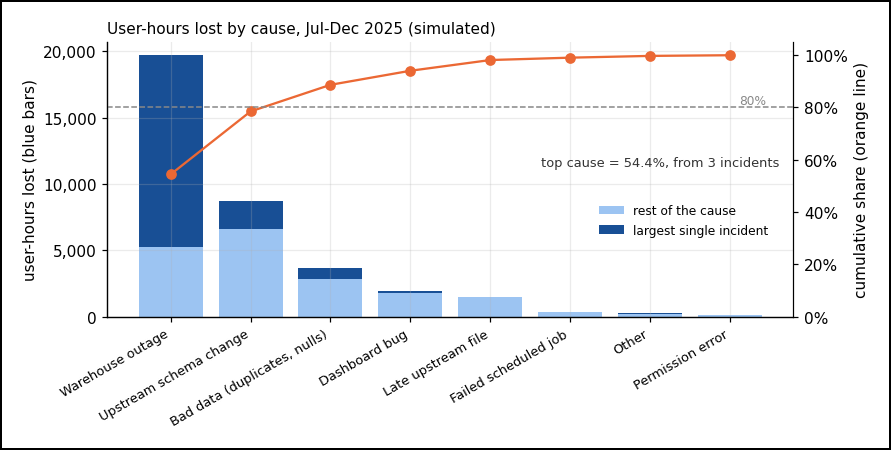

In [8]:
schema_h2 = h2[h2["category"] == "Upstream schema change"]
ren1 = (schema_h1["sub_cause"] == "Column renamed").sum()
ren2 = (schema_h2["sub_cause"] == "Column renamed").sum()
print("Schema-change incidents by kind, before and after the fix (1 Jul):\n")
k1, k2 = schema_h1["sub_cause"].value_counts(), schema_h2["sub_cause"].value_counts()
show(pd.DataFrame({"kind of change": ["Column renamed (fixed)", "Column type changed", "Column dropped"],
                   "incidents Jan-Jun": [k1.get(k, 0) for k in ["Column renamed", "Column type changed", "Column dropped"]],
                   "incidents Jul-Dec": [k2.get(k, 0) for k in ["Column renamed", "Column type changed", "Column dropped"]]}))
print(f"\nSchema-change user-hours lost: Jan-Jun = {schema_h1['user_hours_lost'].sum():,.0f}, Jul-Dec = {schema_h2['user_hours_lost'].sum():,.0f}")

after = pareto_table(h2, "user_hours", "user-hours")
print("\nUser-hours lost by cause, Jul-Dec:\n")
show(pd.DataFrame({
    "cause": after["category"],
    "user-hours lost": after["user_hours"].map("{:,.0f}".format),
    "% of user-hours lost": after["share"].map("{:.1%}".format),
    "cumulative %": after["cumulative"].map("{:.1%}".format),
    "incidents": after["incidents"],
    "largest single incident": after["largest"].map("{:,.0f}".format),
    "largest as % of cause's user-hours": (after["largest"] / after["user_hours"]).map("{:.0%}".format),
}))
wo = h2[h2["category"] == "Warehouse outage"]["user_hours_lost"]
print(f"\nWarehouse outages Jul-Dec without the largest one = {wo.sum():,.0f} − {wo.max():,.0f} = {wo.sum() - wo.max():,.0f} user-hours")
pareto_chart(after, "user_hours", "user-hours lost (blue bars)", "User-hours lost by cause, Jul-Dec 2025 (simulated)",
             f"top cause = {after['share'].iloc[0]:.1%}, from {after['incidents'].iloc[0]} incidents", split=True)

**Observation:** renamed-column incidents fell from 12 to 2, consistent with the fix. But the kinds the fix did not touch fell too (8 to 2, and 5 to 2), so this table alone can't prove the fix caused the drop. Here it is known, because the fix is planted in the simulation; with real data, a before-and-after drop is evidence, not proof.

The Jul–Dec chart has a new top bar: warehouse outage, 54.4% of user-hours lost, from 3 incidents. The largest alone is 14,464 of 19,715 (73%). But outages happened in both halves (2, then 3), and without the largest one the other two still cost 5,251 user-hours, more than bad data (3,695). So outages are a real candidate for the next project, not noise.

## Exercise — A different goal

The data team's manager says the problem is not user pain, but the on-call engineers: they are paged for every incident, and they are burning out. Using the Jan–Jun data, which project should come first now, and how much of the paging would it remove?

In [9]:
print("Incidents by cause, Jan-Jun (each incident = one page to on-call):")
for _, r in by_count.head(3).iterrows():
    print(f"  {r['category']}: incidents = {r['incidents']}, share of pages = {r['share']:.1%}, cumulative = {r['cumulative']:.1%}")

Incidents by cause, Jan-Jun (each incident = one page to on-call):
  Late upstream file: incidents = 121, share of pages = 39.8%, cumulative = 39.8%
  Failed scheduled job: incidents = 70, share of pages = 23.0%, cumulative = 62.8%
  Permission error: incidents = 30, share of pages = 9.9%, cumulative = 72.7%


**Answer:** with on-call pages as the goal, the measure is the **count** of incidents, so the project is **late upstream files**: 121 incidents, at most 39.8% of all pages (if the fix prevented every one). Fixing failed scheduled jobs as well: at most 62.8%.

The same data gives a different project because the goal changed. The goal decides the measure, and the measure decides the project.

## Key takeaways

- **A Pareto chart sorts causes from largest to smallest and adds a cumulative line.** The first few bars, the vital few, are where a project pays off most.
- **80/20 is a rule of thumb.** Here two causes made up 62.8% of incidents, and one cause made up 71.8% of user-hours lost; the chart is how you find out.
- **The measure must match the goal.** By count, late upstream files came first (39.8%); by user-hours lost, upstream schema changes came first (71.8%, from 8.2% of incidents).
- **Check the largest single incident.** Warehouse outages topped the Jul–Dec chart (54.4%) from 3 incidents, one of them 73% of the cause's user-hours; without it, outages still rank above bad data.
- **Drill in, then re-check.** A nested Pareto found renamed columns as the biggest piece of schema changes. After the fix, those incidents fell from 12 to 2, but untargeted kinds fell too, so a before-and-after drop alone is evidence, not proof.
- **In DMAIC, Pareto is a Define tool:** it picks the project and gives the problem statement its "how big".